# UERANSIM plots (simulation, core-network baseline)

UERANSIM simulates the gNB and UE without a radio physical layer, so these runs show the behaviour of the
**core networks on their own** (Open5GS vs free5GC), without the cost and limits of a real or simulated radio.
There is only a monolithic setup, so there are two configurations.

The notebook makes three figures in the same style as the other simulation figures, each with a summary table:

1. **Control plane:** registration time and PDU session setup time
2. **User plane:** throughput, RTT and jitter
3. **Resource usage:** CPU, memory and power, saturation on top and fixed load underneath

**Before running:** put this notebook next to your `5g_open_source_benchmarking` folder,
or change `RESULTS_DIR` in the first code cell. Figures are saved as PNG and PDF in the `figures` folder.

In [1]:
import re
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

%config InlineBackend.figure_format = "retina"

# ---- Settings you may need to change ----
RESULTS_DIR = Path("5g_open_source_benchmarking/results")
OUTPUT_DIR = Path("figures")
OUTPUT_DIR.mkdir(exist_ok=True)

# ---- Colours (same as the other notebooks) ----
PALETTES = {
    "blue_coral":       {"open5gs": "#1F6FB2", "free5gc": "#EE6B5E"},
    "navy_coral":       {"open5gs": "#1F3A5F", "free5gc": "#EE6B5E"},
    "blue_vermillion":  {"open5gs": "#0072B2", "free5gc": "#D55E00"},
    "teal_coral":       {"open5gs": "#00798C", "free5gc": "#D1495B"},
    "navy_gold":        {"open5gs": "#1F3A5F", "free5gc": "#E3A72F"},
    "purple_green":     {"open5gs": "#5E4FA2", "free5gc": "#3AA17E"},
}
PALETTE = "blue_coral"
CORE_COLOURS = PALETTES[PALETTE]
CORE_NAMES = {"open5gs": "Open5GS", "free5gc": "free5GC"}
OUTLINE = "#222222"

# Resource figure: colours show components
COMPONENT_COLOURS = {"gNB": "#1F6FB2", "5GC": "#EE6B5E", "UE (sim)": "#C9C9C9"}
HOST_COLOURS = {"RAN host": "#1F6FB2", "Core host": "#EE6B5E"}

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

# ---- The two UERANSIM configurations: (core, run folder) ----
FOLDER = "5g_benchmark_results"
CONFIGS = [("open5gs", "open5gs_ueransim"), ("free5gc", "free5gc_ueransim")]
LABELS = [f"{CORE_NAMES[c]}\n+ UERANSIM" for c, _ in CONFIGS]

## Loading the data and shared helpers

- `runs` holds the three UERANSIM runs per core from `all_results.csv`.
- `load_pings` reads every individual ping from the raw `ping_100.txt` files (UE → 8.8.8.8, as in the other simulations).
- `load_power` / `load_fixed_power` recompute average power from the raw RAPL files (decimals instead of whole watts).

In [2]:
all_runs = pd.read_csv(RESULTS_DIR / FOLDER / "all_results.csv")
runs = all_runs[all_runs["ran"] == "ueransim"]


def rows_for(core):
    return runs[runs["core"] == core]


def ci95(values):
    values = np.asarray(values, dtype=float)
    if len(values) < 2:
        return 0.0
    return stats.t.ppf(0.975, len(values) - 1) * values.std(ddof=1) / np.sqrt(len(values))


def load_pings(run_folder, name="ping_100.txt"):
    times = []
    for path in sorted(glob.glob(str(RESULTS_DIR / FOLDER / "round*" / run_folder / "raw" / name))):
        times += [float(t) for t in re.findall(r"time=([\d.]+)", Path(path).read_text(errors="ignore"))]
    return np.array(times)


def read_power_file(path):
    text = Path(path).read_text(errors="ignore")
    joules = float(re.search(r"Total energy\s*\(J\)\s*:\s*([\d.]+)", text).group(1))
    seconds = float(re.search(r"Duration\s*\(s\)\s*:\s*([\d.]+)", text).group(1))
    return joules / seconds


def load_power(run_folder):
    rows = []
    for rnd in sorted((RESULTS_DIR / FOLDER).glob("round*")):
        raw = rnd / run_folder / "raw"
        if (raw / "power_ran.txt").exists():
            rows.append({"RAN host": read_power_file(raw / "power_ran.txt"),
                         "Core host": read_power_file(raw / "power_core.txt")})
    return pd.DataFrame(rows)


def load_fixed_power(run_folder):
    rows = []
    for rnd in sorted((RESULTS_DIR / FOLDER).glob("round*")):
        f = rnd / run_folder / "raw" / "fixed_load" / "power.txt"
        if f.exists():
            vals = dict(re.findall(r"(\w+)=([\d.]+)", f.read_text(errors="ignore")))
            dur = float(vals["duration_s"])
            rows.append({"RAN host": float(vals["ran_joules"]) / dur,
                         "Core host": float(vals["core_joules"]) / dur})
    return pd.DataFrame(rows)


def styled_bar(ax, x, height, core, width=0.6):
    ax.bar(x, height, width, color=CORE_COLOURS[core], edgecolor=OUTLINE, linewidth=1)


def finish(ax, ylabel, title=None, xticks=True):
    if xticks:
        ax.set_xticks(range(len(CONFIGS)))
        ax.set_xticklabels(LABELS, fontsize=9)
        ax.set_xlim(-0.7, len(CONFIGS) - 0.3)
    ax.set_ylabel(ylabel)
    if title:
        ax.set_title(title)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)


def save(fig, name):
    fig.savefig(OUTPUT_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(OUTPUT_DIR / f"{name}.pdf", bbox_inches="tight")
    print(f"Saved {name}.png and .pdf in {OUTPUT_DIR}")

## 1. Control plane

Bar = mean of 3 runs, dots = individual runs (as in the simulation control-plane figures).
Registration and PDU session setup are separate panels because their scales differ.

Saved ueransim_control_plane.png and .pdf in figures


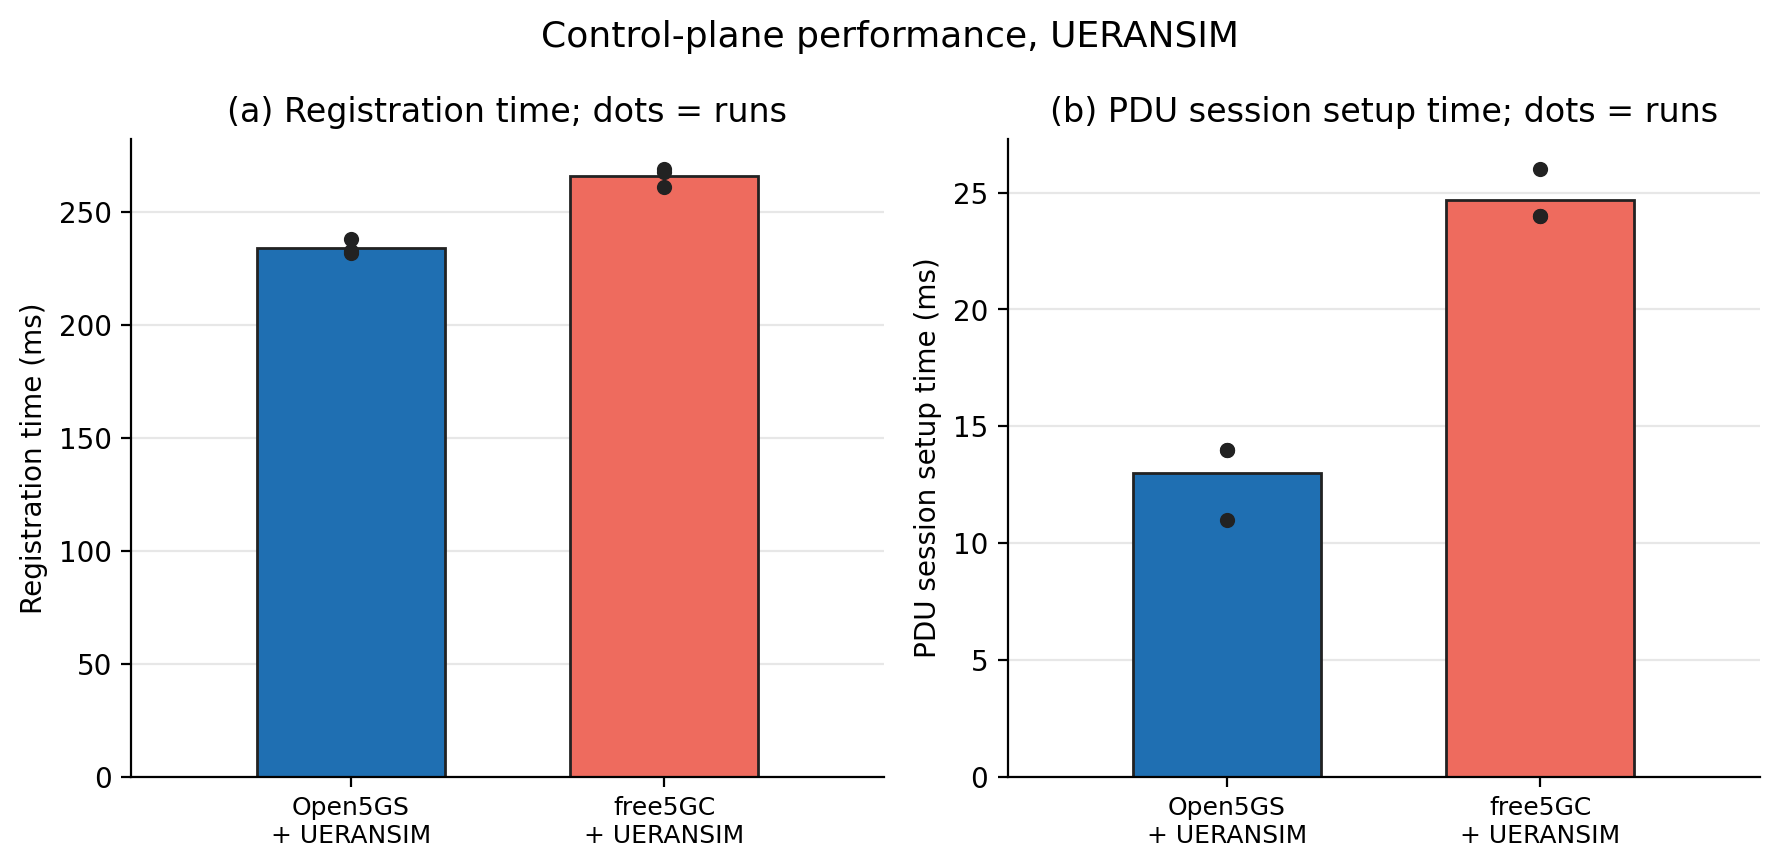

,Attach success,Registration mean (ms),Registration min–max (ms),PDU setup mean (ms),PDU setup min–max (ms)
Core,,,,,
Open5GS,3/3,234.3,232–238,13.0,11–14
free5GC,3/3,266.0,261–269,24.7,24–26


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.4))
cp_table = []
for ax, (metric, title, ylabel) in zip(axes, [
        ("reg_ms", "(a) Registration time; dots = runs", "Registration time (ms)"),
        ("pdu_setup_ms", "(b) PDU session setup time; dots = runs", "PDU session setup time (ms)")]):
    for k, (core, _) in enumerate(CONFIGS):
        v = rows_for(core)[metric].dropna().values
        styled_bar(ax, k, v.mean(), core)
        ax.scatter([k] * len(v), v, color=OUTLINE, s=20, zorder=4)
    finish(ax, ylabel, title)

for core, _ in CONFIGS:
    r = rows_for(core)
    cp_table.append({"Core": CORE_NAMES[core],
                     "Attach success": f"{(r['status'] == 'PASS').sum()}/{len(r)}",
                     "Registration mean (ms)": round(r["reg_ms"].mean(), 1),
                     "Registration min–max (ms)": f"{r['reg_ms'].min():.0f}–{r['reg_ms'].max():.0f}",
                     "PDU setup mean (ms)": round(r["pdu_setup_ms"].mean(), 1),
                     "PDU setup min–max (ms)": f"{r['pdu_setup_ms'].min():.0f}–{r['pdu_setup_ms'].max():.0f}"})

fig.suptitle("Control-plane performance, UERANSIM", fontsize=13)
fig.tight_layout()
save(fig, "ueransim_control_plane")
plt.show()
cp_table = pd.DataFrame(cp_table).set_index("Core")
display(cp_table)

## 2. User plane

- **(a) Throughput:** bar = mean of 3 runs, error bar = 95% confidence interval; downlink and uplink side by side.
- **(b) RTT:** box plot of all 300 pings to 8.8.8.8 (box = middle 50%, line = median, whiskers = fastest/slowest).
  A second table below also gives the RTT from the UE to the core host (`ping_core.txt`), which excludes the internet path.
- **(c) Jitter:** bar = mean of 3 runs, dots = individual runs.

Saved ueransim_user_plane.png and .pdf in figures


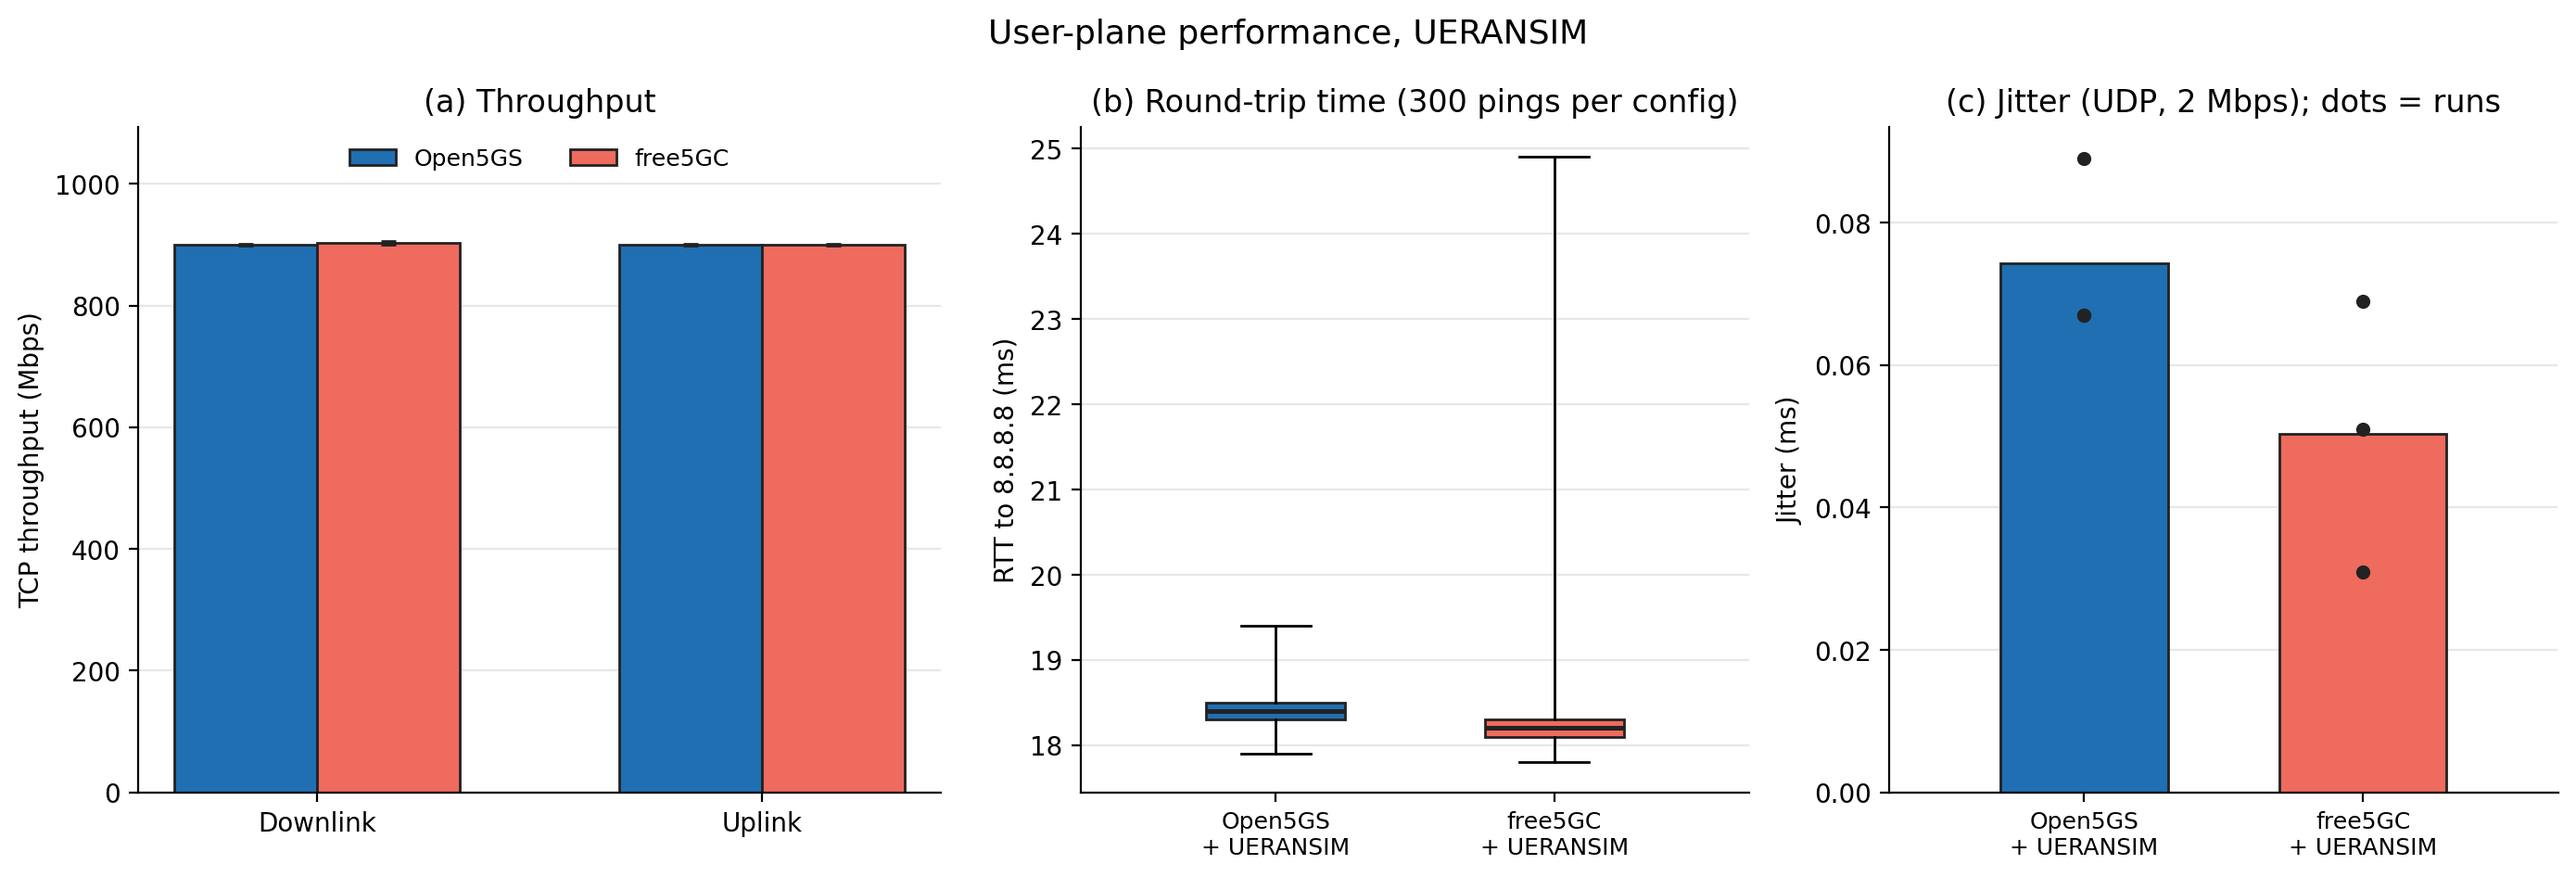

,DL (Mbps),UL (Mbps),RTT to 8.8.8.8 mean (ms),RTT to 8.8.8.8 median (ms),RTT to core host mean (ms),Jitter (ms),Ping loss (%)
Core,,,,,,,
Open5GS,899.7,899.7,18.38,18.4,0.99,0.074,0.0
free5GC,902.7,899.7,18.25,18.2,0.90,0.050,0.0


In [4]:
fig, (ax_tp, ax_rtt, ax_jit) = plt.subplots(1, 3, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.2, 1, 1]})

# (a) throughput: x = direction, one bar per core
width = 0.32
for k, (core, _) in enumerate(CONFIGS):
    r = rows_for(core)
    for j, metric in enumerate(["tcp_dl_mbps", "tcp_ul_mbps"]):
        v = r[metric].dropna().values
        x = j + (k - 0.5) * width
        ax_tp.bar(x, v.mean(), width, color=CORE_COLOURS[core], edgecolor=OUTLINE, linewidth=1,
                  label=CORE_NAMES[core] if j == 0 else None)
        ax_tp.errorbar(x, v.mean(), yerr=ci95(v), color=OUTLINE, capsize=3, linewidth=1.2)
ax_tp.set_xticks([0, 1])
ax_tp.set_xticklabels(["Downlink", "Uplink"])
ax_tp.set_ylim(0, ax_tp.get_ylim()[1] * 1.15)             # room above the bars for the legend
ax_tp.legend(frameon=False, fontsize=9, loc="upper center", ncol=2)
finish(ax_tp, "TCP throughput (Mbps)", "(a) Throughput", xticks=False)

# (b) RTT box plot
pings = [load_pings(run) for _, run in CONFIGS]
box = ax_rtt.boxplot(pings, positions=range(len(CONFIGS)), widths=0.5, patch_artist=True, whis=(0, 100),
                     showfliers=False, medianprops=dict(color=OUTLINE, linewidth=1.8))
for patch, (core, _) in zip(box["boxes"], CONFIGS):
    patch.set_facecolor(CORE_COLOURS[core])
    patch.set_edgecolor(OUTLINE)
finish(ax_rtt, "RTT to 8.8.8.8 (ms)", f"(b) Round-trip time ({len(pings[0])} pings per config)")

# (c) jitter
for k, (core, _) in enumerate(CONFIGS):
    v = rows_for(core)["jitter_ms"].dropna().values
    styled_bar(ax_jit, k, v.mean(), core)
    ax_jit.scatter([k] * len(v), v, color=OUTLINE, s=20, zorder=4)
finish(ax_jit, "Jitter (ms)", "(c) Jitter (UDP, 2 Mbps); dots = runs")

fig.suptitle("User-plane performance, UERANSIM", fontsize=13)
fig.tight_layout()
save(fig, "ueransim_user_plane")
plt.show()

up_table = []
for (core, run), p in zip(CONFIGS, pings):
    r, pc = rows_for(core), load_pings(run, "ping_core.txt")
    up_table.append({"Core": CORE_NAMES[core],
                     "DL (Mbps)": round(r["tcp_dl_mbps"].mean(), 1), "UL (Mbps)": round(r["tcp_ul_mbps"].mean(), 1),
                     "RTT to 8.8.8.8 mean (ms)": round(p.mean(), 2), "RTT to 8.8.8.8 median (ms)": round(np.median(p), 2),
                     "RTT to core host mean (ms)": round(pc.mean(), 2) if len(pc) else np.nan,
                     "Jitter (ms)": round(r["jitter_ms"].mean(), 3), "Ping loss (%)": r["ping_loss_pct"].mean()})
up_table = pd.DataFrame(up_table).set_index("Core")
display(up_table)

## 3. Resource usage (saturation on top, fixed load underneath)

Same layout as the combined simulation resource figure. Columns: CPU per component, memory per component, average power per host;
each column uses the same y-axis scale in both rows. The simulated UE (grey) is simulator overhead.
The UE's memory was only recorded in the fixed-load phase, so the memory column shows the gNB and the 5GC only.

Saved ueransim_resources_combined.png and .pdf in figures


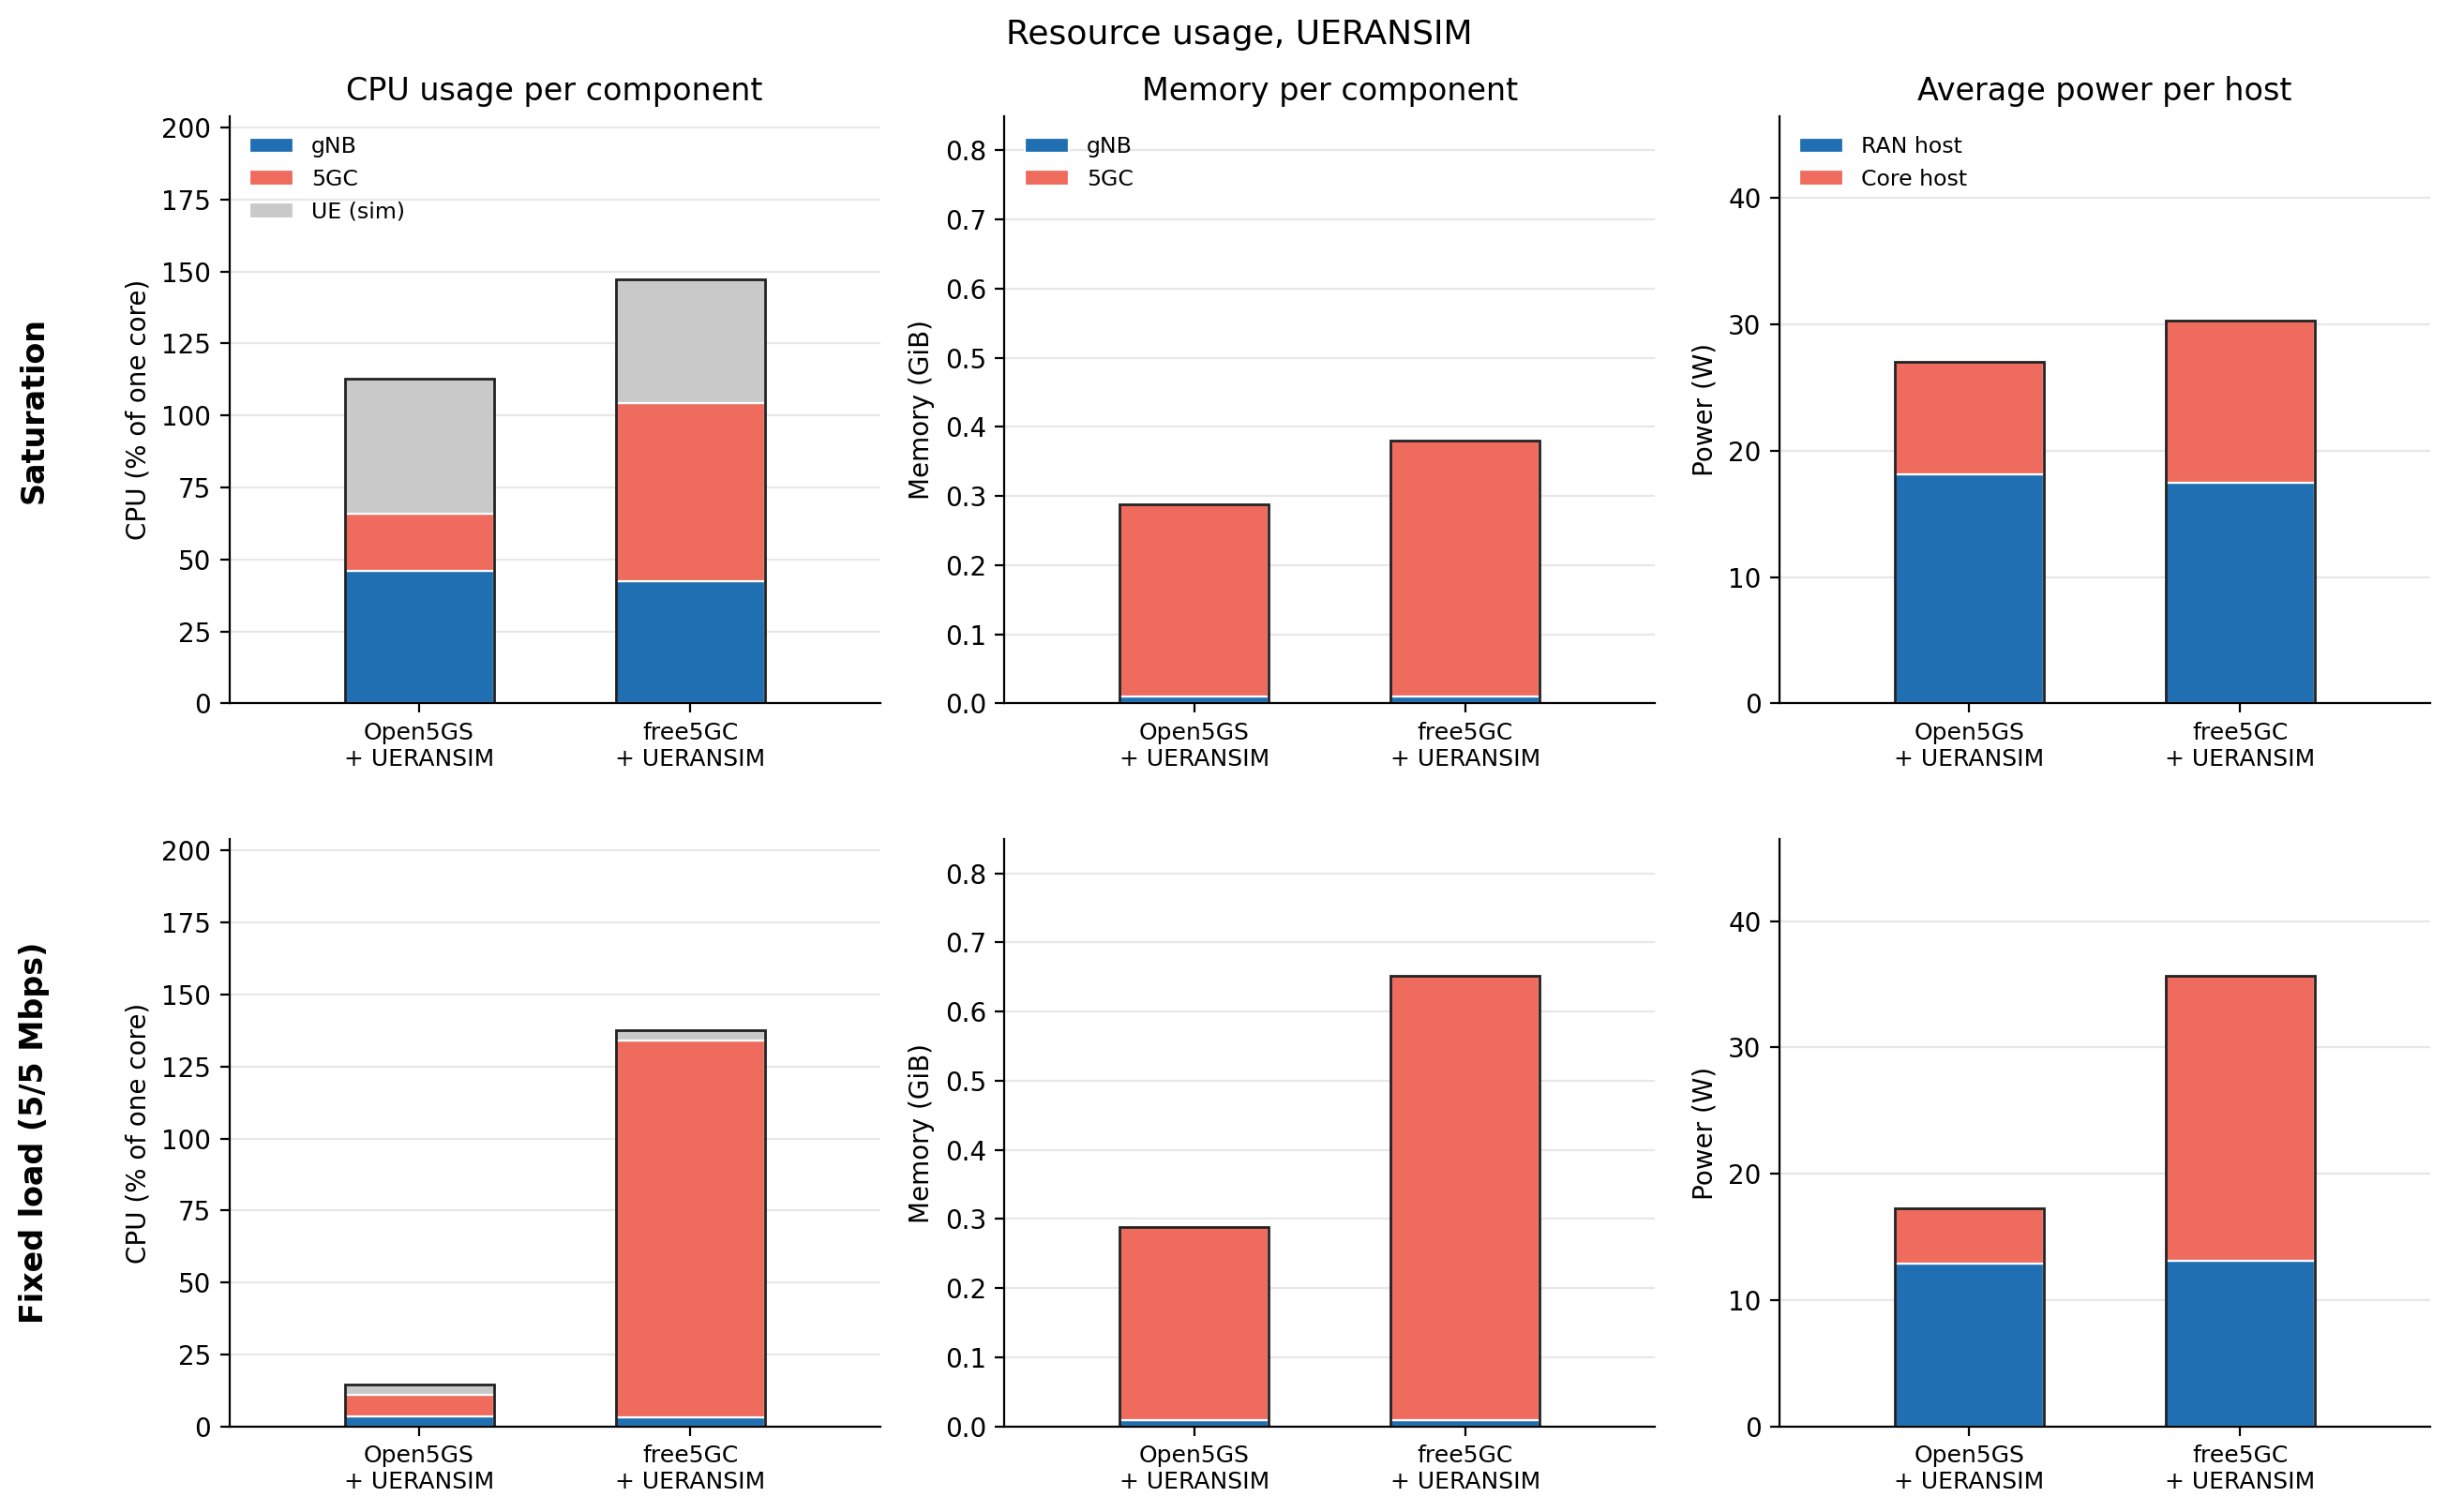

,Fixed load valid,gNB CPU sat/fixed (%),UE CPU sat/fixed (%),5GC CPU sat/fixed (%),5GC memory (GiB),gNB memory (MiB),"UE memory, fixed (MiB)",RAN host power sat/fixed (W),Core host power sat/fixed (W)
Core,,,,,,,,,
Open5GS,3/3,46.1 / 3.5,47.1 / 3.6,19.7 / 7.5,0.28,9.8,6.8,18.1 / 12.9,8.9 / 4.4
free5GC,3/3,42.5 / 3.2,43.0 / 3.6,61.7 / 131.0,0.37,9.7,7.0,17.5 / 13.1,12.8 / 22.6


In [5]:
def stacked(ax, x, parts, colours, width=0.55):
    bottom = 0
    for name, value in parts.items():
        if value > 0:
            ax.bar(x, value, width, bottom=bottom, color=colours[name], edgecolor="white", linewidth=0.8, label=name)
            bottom += value
    ax.bar(x, bottom, width, fill=False, edgecolor=OUTLINE, linewidth=1)


def legend_once(ax):
    handles, labels = ax.get_legend_handles_labels()
    unique = dict(zip(labels, handles))
    order = [n for n in list(COMPONENT_COLOURS) + list(HOST_COLOURS) if n in unique]
    ax.legend([unique[n] for n in order], order, frameon=False, fontsize=8.5, loc="upper left")


def components(r, prefix=""):
    p = prefix
    cpu = {"gNB": r[f"{p}gnb_cpu_pct"].mean(), "5GC": r[f"{p}core_cpu_pct"].mean(), "UE (sim)": r[f"{p}ue_cpu_pct"].mean()}
    mem = {"gNB": r[f"{p}gnb_rss_kb"].mean() / 1024**2, "5GC": r[f"{p}core_rss_kb"].mean() / 1024**2}
    return cpu, mem


fig, axes = plt.subplots(2, 3, figsize=(13, 8.2), sharey="col")
res_table = []
for k, (core, run) in enumerate(CONFIGS):
    r = rows_for(core)
    cpu_s, mem_s = components(r)
    cpu_f, mem_f = components(r, "fl_")
    pwr_s, pwr_f = load_power(run), load_fixed_power(run)
    for row, (cpu, mem, pwr) in enumerate(((cpu_s, mem_s, pwr_s), (cpu_f, mem_f, pwr_f))):
        stacked(axes[row, 0], k, cpu, COMPONENT_COLOURS)
        stacked(axes[row, 1], k, mem, COMPONENT_COLOURS)
        stacked(axes[row, 2], k, pwr.mean().to_dict(), HOST_COLOURS)
    res_table.append({
        "Core": CORE_NAMES[core],
        "Fixed load valid": f"{(r['fl_valid'] == 'VALID').sum()}/{len(r)}",
        "gNB CPU sat/fixed (%)": f"{cpu_s['gNB']:.1f} / {cpu_f['gNB']:.1f}",
        "UE CPU sat/fixed (%)": f"{cpu_s['UE (sim)']:.1f} / {cpu_f['UE (sim)']:.1f}",
        "5GC CPU sat/fixed (%)": f"{cpu_s['5GC']:.1f} / {cpu_f['5GC']:.1f}",
        "5GC memory (GiB)": round(mem_s["5GC"], 2),
        "gNB memory (MiB)": round(mem_s["gNB"] * 1024, 1),
        "UE memory, fixed (MiB)": round(r["fl_ue_rss_kb"].mean() / 1024, 1),
        "RAN host power sat/fixed (W)": f"{pwr_s['RAN host'].mean():.1f} / {pwr_f['RAN host'].mean():.1f}",
        "Core host power sat/fixed (W)": f"{pwr_s['Core host'].mean():.1f} / {pwr_f['Core host'].mean():.1f}",
    })

col_titles = ["CPU usage per component", "Memory per component", "Average power per host"]
y_labels = ["CPU (% of one core)", "Memory (GiB)", "Power (W)"]
row_titles = ["Saturation", "Fixed load (5/5 Mbps)"]
for row in range(2):
    for c in range(3):
        ax = axes[row, c]
        finish(ax, y_labels[c], col_titles[c] if row == 0 else None)
        ax.yaxis.set_tick_params(labelleft=True)
        if row == 0:
            legend_once(ax)
    axes[row, 0].annotate(row_titles[row], xy=(-0.3, 0.5), xycoords="axes fraction", rotation=90,
                          ha="center", va="center", fontsize=12, fontweight="bold")
for c in range(3):
    n = len(axes[0, c].get_legend().get_texts())
    top = max(axes[0, c].get_ylim()[1], axes[1, c].get_ylim()[1])
    axes[0, c].set_ylim(0, top * (1.08 + 0.08 * n))

fig.suptitle("Resource usage, UERANSIM", fontsize=13)
fig.tight_layout(h_pad=2.5)
save(fig, "ueransim_resources_combined")
plt.show()
res_table = pd.DataFrame(res_table).set_index("Core")
display(res_table)

## Optional: save the summary tables

CSV files for Excel, plus LaTeX versions.

In [6]:
for name, table in [("control_plane", cp_table), ("user_plane", up_table), ("resources", res_table)]:
    table.to_csv(OUTPUT_DIR / f"ueransim_{name}_summary.csv")
    print(f"--- {name} ---")
    print(table.to_latex(float_format="%.2f").replace("%", r"\%").replace("–", "--"))

--- control_plane ---
\begin{tabular}{llrlrl}
\toprule
 & Attach success & Registration mean (ms) & Registration min--max (ms) & PDU setup mean (ms) & PDU setup min--max (ms) \\
Core &  &  &  &  &  \\
\midrule
Open5GS & 3/3 & 234.30 & 232--238 & 13.00 & 11--14 \\
free5GC & 3/3 & 266.00 & 261--269 & 24.70 & 24--26 \\
\bottomrule
\end{tabular}

--- user_plane ---
\begin{tabular}{lrrrrrrr}
\toprule
 & DL (Mbps) & UL (Mbps) & RTT to 8.8.8.8 mean (ms) & RTT to 8.8.8.8 median (ms) & RTT to core host mean (ms) & Jitter (ms) & Ping loss (\%) \\
Core &  &  &  &  &  &  &  \\
\midrule
Open5GS & 899.70 & 899.70 & 18.38 & 18.40 & 0.99 & 0.07 & 0.00 \\
free5GC & 902.70 & 899.70 & 18.25 & 18.20 & 0.90 & 0.05 & 0.00 \\
\bottomrule
\end{tabular}

--- resources ---
\begin{tabular}{lllllrrrll}
\toprule
 & Fixed load valid & gNB CPU sat/fixed (\%) & UE CPU sat/fixed (\%) & 5GC CPU sat/fixed (\%) & 5GC memory (GiB) & gNB memory (MiB) & UE memory, fixed (MiB) & RAN host power sat/fixed (W) & Core host power